In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np

c:\Users\User\miniconda3\envs\clip\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
torch.cuda.is_available()

True

### PositionalEmbedding

A transformer looks at all words (or image patches) at once, so it doesn't know their order. This class fixes that by adding a unique "position signal" (made from sine and cosine waves) to each item in the sequence.

- **Input:** a sequence of vectors.
- **Output:** the same sequence, with position information added.
- The signal is fixed. It is not learned during training.

In [3]:
class PositionalEmbedding(nn.Module):
  def __init__(self, width, max_seq_length):
    super().__init__()

    pe = torch.zeros(max_seq_length, width)

    for pos in range(max_seq_length):
      for i in range(width):
        if i % 2 == 0:
          pe[pos][i] = np.sin(pos/(10000 ** (i/width)))
        else:
          pe[pos][i] = np.cos(pos/(10000 ** ((i-1)/width)))

    self.register_buffer('pe', pe.unsqueeze(0))

  def forward(self, x):

    x = x + self.pe

    return x

### AttentionHead

One "attention head" lets every item in a sequence look at the other items and decide which ones matter most.

- Each item makes a **query** ("what am I looking for?"), a **key** ("what do I contain?") and a **value** ("what information do I give?").
- Queries are compared with keys to get attention scores. The scores are turned into percentages (softmax), and these are used to mix the values.
- An optional **mask** hides items that should be ignored, such as padding.

In [4]:
class AttentionHead(nn.Module):
  def __init__(self, width, head_size):
    super().__init__()
    self.head_size = head_size

    self.query = nn.Linear(width, head_size)
    self.key = nn.Linear(width, head_size)
    self.value = nn.Linear(width, head_size)

  def forward(self, x, mask=None):
    # Obtaining Queries, Keys, and Values
    Q = self.query(x)
    K = self.key(x)
    V = self.value(x)

    # Dot Product of Queries and Keys
    attention = Q @ K.transpose(-2,-1)

    # Scaling
    attention = attention / (self.head_size ** 0.5)

    # Applying Attention Mask
    if mask is not None:
        attention = attention.masked_fill(mask == 0, float("-inf"))

    attention = torch.softmax(attention, dim=-1)

    attention = attention @ V

    return attention

### MultiHeadAttention

Several attention heads working side by side. Each head can focus on a different kind of relationship, and their results are joined together and mixed by one final linear layer.

In [5]:
class MultiHeadAttention(nn.Module):
  def __init__(self, width, n_heads):
    super().__init__()
    self.head_size = width // n_heads

    self.W_o = nn.Linear(width, width)

    self.heads = nn.ModuleList([AttentionHead(width, self.head_size) for _ in range(n_heads)])

  def forward(self, x, mask=None):
    # Combine attention heads
    out = torch.cat([head(x, mask=mask) for head in self.heads], dim=-1)

    out = self.W_o(out)

    return out


### TransformerEncoder

The basic building block of both encoders. It has two steps:

1. **Attention:** items share information with each other.
2. **MLP:** a small neural network processes each item on its own.

Each step is wrapped with layer normalization (to keep values stable) and a skip connection (the input is added back to the output). Blocks like this are stacked on top of each other.

In [6]:
class TransformerEncoder(nn.Module):
    def __init__(self, width, n_heads, r_mlp=4):
        super().__init__()
        self.width = width
        self.n_heads = n_heads

        # Sub-Layer 1 Normalization
        self.ln1 = nn.LayerNorm(width)

        # Multi-Head Attention
        self.mha = MultiHeadAttention(width, n_heads)

        # Sub-Layer 2 Normalization
        self.ln2 = nn.LayerNorm(width)

        # Multilayer Perception
        self.mlp = nn.Sequential(
            nn.Linear(self.width, self.width*r_mlp),
            nn.GELU(),
            nn.Linear(self.width*r_mlp, self.width)
        )


    def forward(self, x, mask=None):
        x = x + self.mha(self.ln1(x), mask=mask)

        x = x + self.mlp(self.ln2(x))

        return x


### Tokenizer
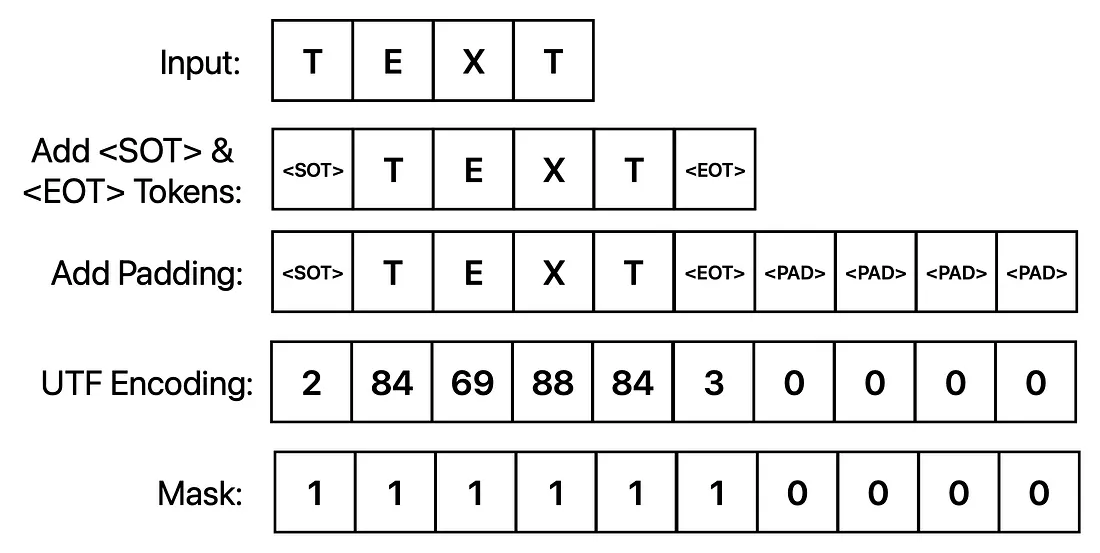

In [ ]:
def tokenizer(text, encode=True, mask=None, max_seq_length=32):
    if encode:
        out = chr(2) + text + chr(3) # Adding SOT and EOT tokens
        out = out + "".join([chr(0) for _ in range(max_seq_length-len(out))]) # Adding Padding
        out = torch.IntTensor(list(out.encode("utf-8"))) # Encoding Text
        mask = torch.ones(len(out.nonzero()))
        mask = torch.cat((mask,torch.zeros(max_seq_length-len(mask)))).type(torch.IntTensor)
    else:
        out = [chr(x) for x in text[1:len(mask.nonzero())-1]]
        out = "".join(out)
        mask = None

    return out, mask
tokenizer("test", encode=True, max_seq_length=32)

(tensor([  2, 116, 101, 120, 116,   3,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0], dtype=torch.int32),
 tensor([1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0], dtype=torch.int32))

### TextEncoder

Turns a caption into a single list of numbers (an **embedding**) that captures its meaning.

1. Convert each character into a vector.
2. Add position information.
3. Pass the result through the transformer blocks.
4. Keep only the output at the end-of-text token, which summarizes the whole sentence.
5. Project it into the shared image-text space and scale it for the cosine similarity calculation afterward.

In [8]:
class TextEncoder(nn.Module):
    def __init__(self, vocab_size, width, max_seq_length, n_heads, n_layers, emb_dim):
        super().__init__()

        self.max_seq_length = max_seq_length

        self.encoder_embedding = nn.Embedding(vocab_size, width)

        self.positional_embedding = PositionalEmbedding(width, max_seq_length)

        self.encoder = nn.ModuleList([TransformerEncoder(width,n_heads) for _ in range(n_layers)])

        # learned proj of image to embed
        self.projection = nn.Parameter(torch.randn(width, emb_dim))

    def forward(self, text, mask=None):
        # Text Embedding
        x = self.encoder_embedding(text)

        # Positional Embedding
        x = self.positional_embedding(x)

        # Transformer Encoder
        for encoder_layer in self.encoder:
            x = encoder_layer(x, mask=mask)

        # Takes features from the EOT Embedding
        x = x[torch.arange(text.shape[0]), torch.sub(torch.sum(mask[:,0],dim=1),1)]

        # joint multimodal embedding
        if self.projection is not None:
            x = x @ self.projection

        x = x / torch.norm(x, dim=-1, keepdim=True)

        return x


### ImageEncoder

Turns an image into an embedding of the same size as the text embedding. It is a Vision Transformer (ViT).

1. Cut the image into small square **patches**.
2. Turn each patch into a vector.
3. Add a special **class token** at the start. It will collect a summary of the whole image.
4. Add position information and pass everything through the transformer blocks.
5. Keep only the class token's output, project it into the shared space and scale it for the cosine similarity calculation afterward.

In [9]:
class ImageEncoder(nn.Module):
    def __init__(self, width, img_size, patch_size, n_channels, n_layers, n_heads, emb_dim):
        super().__init__()

        assert img_size[0] % patch_size[0] == 0 and img_size[1] % patch_size[1] == 0, "img_size dimensions must be divisible by patch_size dimensions"
        assert width % n_heads == 0, "width must be divisible by n_heads"

        self.n_patches = (img_size[0] * img_size[1]) // (patch_size[0] * patch_size[1])

        self.max_seq_length = self.n_patches + 1

        self.linear_project = nn.Conv2d(n_channels, width, kernel_size=patch_size, stride=patch_size)

        self.cls_token = nn.Parameter(torch.randn(1, 1, width))

        self.positional_embedding = PositionalEmbedding(width,self.max_seq_length)

        self.encoder = nn.ModuleList([TransformerEncoder(width,n_heads) for _ in range(n_layers)])


        # learned proj of image to embed
        self.projection = nn.Parameter(torch.randn(width, emb_dim))


    def forward(self,x):
        # Patch Embedding
        x = self.linear_project(x)
        x = x.flatten(2).transpose(1, 2)

        # Positional Embedding
        x = torch.cat((self.cls_token.expand(x.size()[0], -1, -1),x), dim=1)
        x = self.positional_embedding(x)

        # Transformer Encoder
        for encoder_layer in self.encoder:
            x = encoder_layer(x)

        # Getting Class Tokens
        x = x[:, 0, :]

        # joint multimodal embedding
        if self.projection is not None:
            x = x @ self.projection

        x = x / torch.norm(x, dim=-1, keepdim=True)

        return x


### Image Preprocess
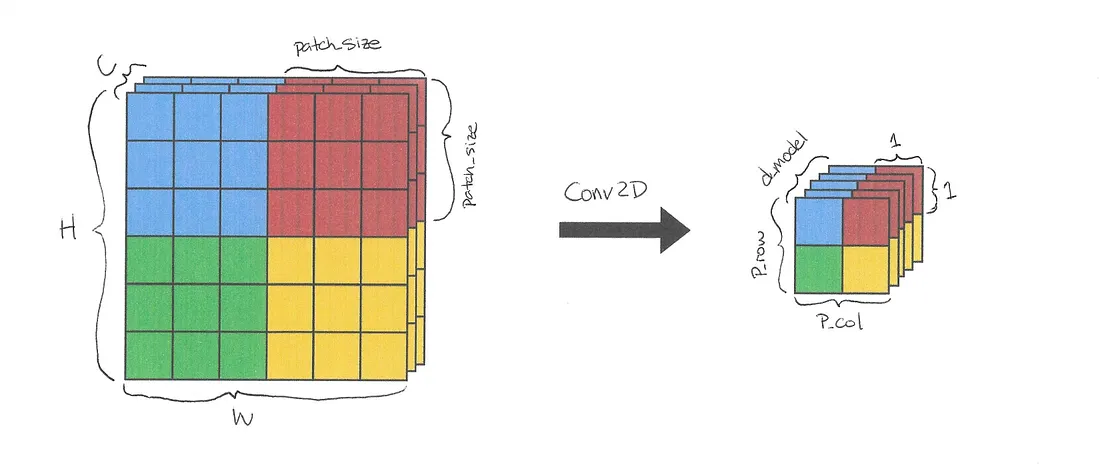
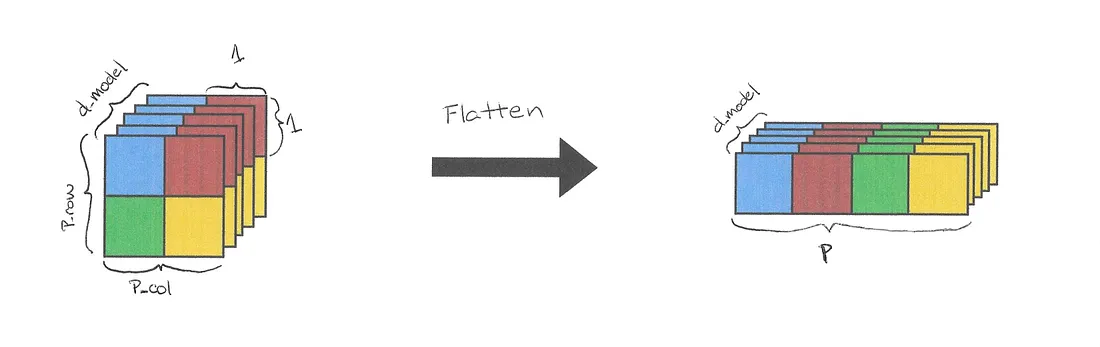
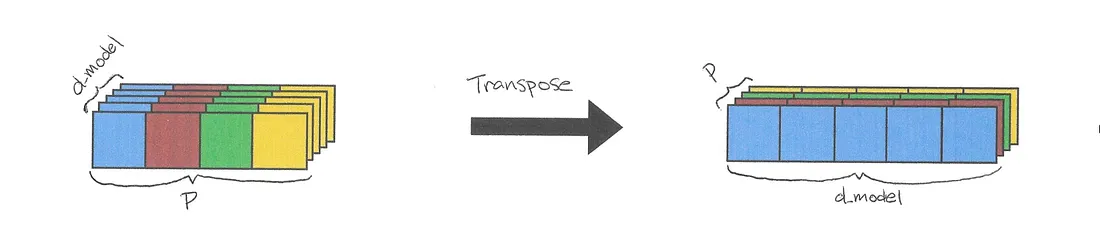

### CLIP

Combines the image encoder and the text encoder, and trains them together.

The idea: for a batch of images with their captions, the embedding of each image should be **close to its own caption** and **far from the other captions**.

1. Encode the images and the captions.
2. Compare every image with every caption to get a table of similarity scores.
3. The correct pairs are on the diagonal of the table. The loss rewards high scores there and low scores everywhere else.

The model returns this loss during training. After training, use the two encoders to compare images and text.

In [10]:
class CLIP(nn.Module):
    def __init__(self, emb_dim, vit_width, img_size, patch_size, n_channels, vit_layers, vit_heads, vocab_size, text_width, max_seq_length, text_heads, text_layers):
        super().__init__()

        self.image_encoder = ImageEncoder(vit_width, img_size, patch_size, n_channels, vit_layers, vit_heads, emb_dim)

        self.text_encoder = TextEncoder(vocab_size, text_width, max_seq_length, text_heads, text_layers, emb_dim)

        self.temperature = nn.Parameter(torch.ones([]) * np.log(1 / 0.07))

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


    def forward(self, image, text, mask=None):
        I_e = self.image_encoder(image)
        T_e = self.text_encoder(text, mask=mask)

        # scaled pairwise cosine similarities [n, n]
        logits = (I_e @ T_e.transpose(-2,-1)) * torch.exp(self.temperature)

        # symmetric loss function
        labels = torch.arange(logits.shape[0]).to(self.device)

        loss_i = nn.functional.cross_entropy(logits.transpose(-2,-1), labels)
        loss_t = nn.functional.cross_entropy(logits, labels)

        loss = (loss_i + loss_t) / 2

        return loss

### FashionMNIST

The dataset used for training. It loads the Fashion-MNIST clothing images and gives each one a simple caption based on its class, for example "An image of a sneaker".

Each item contains:
- the **image**,
- the **caption**, converted to numbers by the tokenizer,
- a **mask** that marks which positions are real text and which are padding.

In [11]:
class FashionMNIST(Dataset):
    def __init__(self, train=True):
        self.dataset = load_dataset("zalando-datasets/fashion_mnist")

        self.transform = T.ToTensor()

        if train:
            self.split = "train"
        else:
            self.split = "test"


        self.captions = {0: "An image of a t-shirt/top",
                        1: "An image of trousers",
                        2: "An image of a pullover",
                        3: "An image of a dress",
                        4: "An image of a coat",
                        5: "An image of a sandal",
                        6: "An image of a shirt",
                        7: "An image of a sneaker",
                        8: "An image of a bag",
                        9: "An image of an ankle boot"}


    def __len__(self):
        return self.dataset.num_rows[self.split]

    def __getitem__(self,i):
        img = self.dataset[self.split][i]["image"]
        img = self.transform(img)

        cap, mask = tokenizer(self.captions[self.dataset[self.split][i]["label"]])

        mask = mask.repeat(len(mask),1)

        return {"image": img, "caption": cap, "mask": mask}

In [12]:
emb_dim = 32
vit_width = 9
img_size = (28,28)
patch_size = (14,14)
n_channels = 1
vit_layers = 3
vit_heads = 3
vocab_size = 256
text_width = 32
max_seq_length = 32
text_heads = 8
text_layers = 4
lr = 1e-3
epochs = 10
batch_size = 128

In [13]:
train_set = FashionMNIST(train = True)
test_set = FashionMNIST(train = False)

train_loader = DataLoader(train_set, shuffle=True, batch_size=batch_size)
test_loader = DataLoader(test_set, shuffle=False, batch_size=batch_size)

Using device:  cuda (NVIDIA GeForce RTX 4060)
Epoch [1/10], Batch Loss: 2.938
Model Saved.
Epoch [2/10], Batch Loss: 2.687
Model Saved.
Epoch [3/10], Batch Loss: 2.747
Epoch [4/10], Batch Loss: 2.871
Epoch [5/10], Batch Loss: 2.821
Epoch [6/10], Batch Loss: 2.717
Epoch [7/10], Batch Loss: 2.727
Epoch [8/10], Batch Loss: 2.661
Model Saved.
Epoch [9/10], Batch Loss: 2.686
Epoch [10/10], Batch Loss: 2.619
Model Saved.


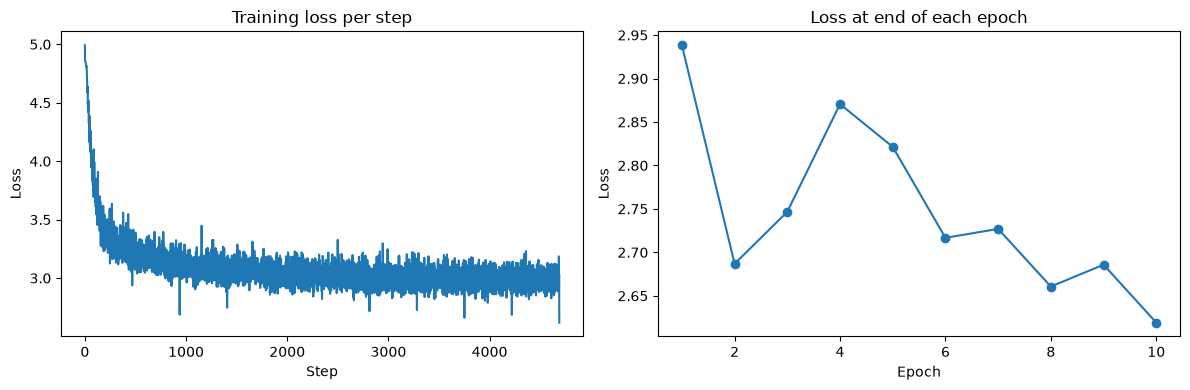

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device: ", device, f"({torch.cuda.get_device_name(device)})" if torch.cuda.is_available() else "")

model = CLIP(emb_dim, vit_width, img_size, patch_size, n_channels, vit_layers, vit_heads, vocab_size, text_width, max_seq_length, text_heads, text_layers).to(device)

optimizer = optim.Adam(model.parameters(), lr=lr)

best_loss = np.inf
batch_losses = []
epoch_losses = []
for epoch in range(epochs):
    for i, data in enumerate(train_loader, 0):
        img, cap, mask = data["image"].to(device), data["caption"].to(device), data["mask"].to(device)
        loss = model(img,cap,mask)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    epoch_losses.append(loss.item())
    print(f"Epoch [{epoch+1}/{epochs}], Batch Loss: {loss.item():.3f}")

    # Saves model if it performed better than the previous best
    if loss.item() <= best_loss:
        best_loss = loss.item()
        torch.save(model.state_dict(), "best.pt")
        print("Model Saved.")

# Plot loss curves and save as image
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(batch_losses)
ax1.set_xlabel("Step"); ax1.set_ylabel("Loss"); ax1.set_title("Training loss per step")
ax2.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker="o")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Loss"); ax2.set_title("Loss at end of each epoch")
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_28236\3870437171.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best.pt", map_location=devi

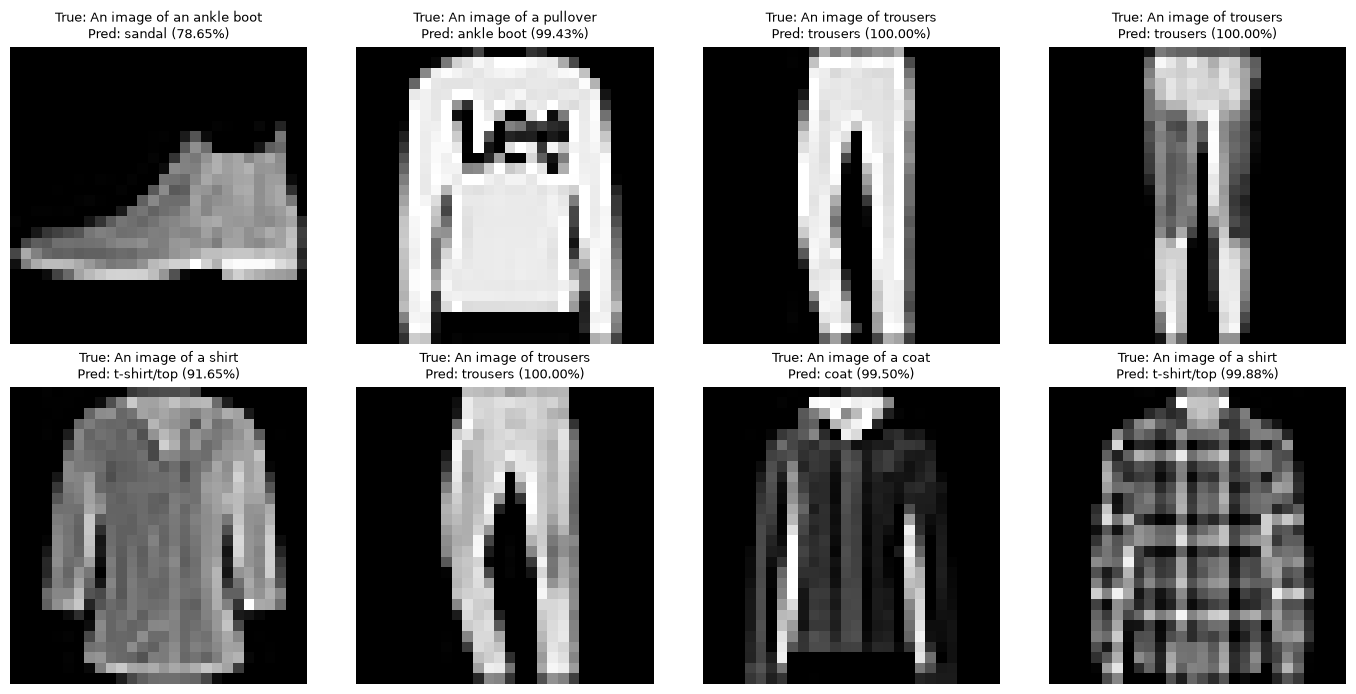

In [15]:
# Loading Best Model
model = CLIP(emb_dim, vit_width, img_size, patch_size, n_channels, vit_layers, vit_heads, vocab_size, text_width, max_seq_length, text_heads, text_layers).to(device)
model.load_state_dict(torch.load("best.pt", map_location=device))
model.eval()


# Captions to compare images to
class_names =["t-shirt/top",
                "trousers",
                "pullover",
                "dress",
                "coat",
                "sandal",
                "shirt",
                "sneaker",
                "bag",
                "ankle boot"]

text = torch.stack([tokenizer(x)[0] for x in class_names]).to(device)
mask = torch.stack([tokenizer(x)[1] for x in class_names])
mask = mask.repeat(1,len(mask[0])).reshape(len(mask),len(mask[0]),len(mask[0])).to(device)

with torch.no_grad():
  text_features = model.text_encoder(text, mask=mask)
text_features /= text_features.norm(dim=-1, keepdim=True)

n_show = 8
start_idx = 0

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.flatten(), range(start_idx, start_idx + n_show)):
    sample = test_set[idx]
    img = sample["image"][None, :].to(device)

    with torch.no_grad():
        image_features = model.image_encoder(img)
    image_features /= image_features.norm(dim=-1, keepdim=True)

    similarity = (100.0 * image_features @ text_features.T).softmax(dim=-1)
    value, index = similarity[0].max(dim=0)

    true_label = tokenizer(sample["caption"], encode=False, mask=sample["mask"][0])[0]

    ax.imshow(sample["image"].permute(1, 2, 0), cmap="gray")
    ax.set_title(f"True: {true_label}\nPred: {class_names[int(index)]} ({100 * value.item():.2f}%)", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()
